## cài đặt thư viện

In [ ]:
# Nếu môi trường chưa có thư viện, bỏ comment dòng dưới để cài đặt
# %pip install -q pandas numpy scikit-learn matplotlib seaborn joblib

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, make_scorer
)
from sklearn.base import BaseEstimator, TransformerMixin, clone

RANDOM_STATE = 42
TARGET = "Attack_type"

def find_data_file(filename: str) -> Path:
    # TÃ¬m file theo vÃ²ng lÃªn thÆ° mÃ»c cha, khÃ´ng phÃ¹ thuá»™c notebook Ä‘Æ°á»£c cháº¡y tá»« Ä‘Ã¢u.
    cwd = Path.cwd().resolve()
    candidates = [
        cwd / filename,
        cwd / "splitted data" / filename,
        cwd / ".." / "splitted data" / filename,
        cwd / ".." / ".." / "splitted data" / filename,
    ]
    # Search project data folders from the notebook directory upwards.
    for parent in (cwd, *cwd.parents):
        candidates.extend([
            parent / "splitted data" / filename,
            parent / "preprocessing" / "data" / filename,
        ])

    for path in candidates:
        path = path.resolve()
        if path.is_file():
            return path

    searched = "\n".join(f"  - {path.resolve()}" for path in candidates)
    raise FileNotFoundError(f"KhÃ´ng tÃ¬m tháº¥y {filename}. ÄÃ£ kiá»ƒm tra:\n{searched}")

# Dữ liệu đã được tạo bởi preprocessing/E08_RF.ipynb.
TRAIN_PATH = Path("../../project/preprocessing/data/E08_RF_Processing/train.csv.gz").resolve()
VALID_PATH = Path("../../project/preprocessing/data/E08_RF_Processing/validation.csv.gz").resolve()
if not TRAIN_PATH.is_file() or not VALID_PATH.is_file():
    raise FileNotFoundError("Hãy chạy toàn bộ preprocessing/E08_RF.ipynb trước khi huấn luyện E08.")

FileNotFoundError: Hãy chạy toàn bộ preprocessing/E08_RF.ipynb trước khi huấn luyện E08.

## đọc dữ liệu và kiểm tra cấu trúc

In [ ]:
train_df = pd.read_csv(TRAIN_PATH)
valid_df = pd.read_csv(VALID_PATH)

print("Train shape:", train_df.shape)
print("Validation shape:", valid_df.shape)
print("\\nCác cột train:")
print(train_df.columns.tolist())

if TARGET not in train_df.columns or TARGET not in valid_df.columns:
    raise ValueError(f"Không tìm thấy cột nhãn '{TARGET}' trong cả hai tập dữ liệu.")

# Chỉ tách X/y, không loại bỏ hay biến đổi đặc trưng.
X_train = train_df.drop(columns=[TARGET]).copy()
y_train = train_df[TARGET].copy()
X_valid = valid_df.drop(columns=[TARGET]).copy()
y_valid = valid_df[TARGET].copy()

missing_cols = [c for c in X_train.columns if c not in X_valid.columns]
extra_cols = [c for c in X_valid.columns if c not in X_train.columns]
if missing_cols or extra_cols:
    raise ValueError(
        f"Cột không khớp giữa train và validation. "
        f"Thiếu ở validation: {missing_cols}; dư ở validation: {extra_cols}"
    )
X_valid = X_valid[X_train.columns]

# Không tự động điền giá trị thiếu vì yêu cầu không xử lý dữ liệu.
if X_train.isna().any().any() or X_valid.isna().any().any():
    raise ValueError("Dữ liệu có giá trị thiếu. Notebook không tự impute; cần xử lý nguồn dữ liệu trước.")

print("\\nSố lớp train:", y_train.nunique())
print("Phân bố lớp train:")
display(y_train.value_counts())

Train shape: (82536, 83)
Validation shape: (17686, 83)
\nCác cột train:
['id.orig_p', 'id.resp_p', 'proto', 'service', 'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_data_pkts_tot', 'bwd_data_pkts_tot', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec', 'flow_pkts_per_sec', 'down_up_ratio', 'fwd_header_size_tot', 'fwd_header_size_min', 'fwd_header_size_max', 'bwd_header_size_tot', 'bwd_header_size_min', 'bwd_header_size_max', 'flow_FIN_flag_count', 'flow_SYN_flag_count', 'flow_RST_flag_count', 'fwd_PSH_flag_count', 'bwd_PSH_flag_count', 'flow_ACK_flag_count', 'fwd_URG_flag_count', 'flow_CWR_flag_count', 'flow_ECE_flag_count', 'fwd_pkts_payload.min', 'fwd_pkts_payload.max', 'fwd_pkts_payload.tot', 'fwd_pkts_payload.avg', 'fwd_pkts_payload.std', 'bwd_pkts_payload.min', 'bwd_pkts_payload.max', 'bwd_pkts_payload.tot', 'bwd_pkts_payload.avg', 'bwd_pkts_payload.std', 'flow_pkts_payload.min', 'flow_pkts_payload.max', 'flow_pkts_payload.tot', 'flow_pkts_payload.avg', 'flow_pkts_payload.std', 'fwd_

Attack_type
DOS_SYN_Hping                 63062
Thing_Speak                    5355
ARP_poisioning                 5334
MQTT_Publish                   2899
NMAP_UDP_SCAN                  1807
NMAP_XMAS_TREE_SCAN            1407
NMAP_OS_DETECTION              1400
NMAP_TCP_scan                   701
DDOS_Slowloris                  373
Wipro_bulb                      153
Metasploit_Brute_Force_SSH       25
NMAP_FIN_SCAN                    20
Name: count, dtype: int64

## xây dựng pipeline cho E08

In [ ]:
class NumericCorrelationFilter(BaseEstimator, TransformerMixin):
    # Drop redundant numeric columns using correlations learned at fit time.

    def __init__(self, threshold=0.98):
        self.threshold = threshold

    def fit(self, X, y=None):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("NumericCorrelationFilter requires a pandas DataFrame.")

        self.feature_names_in_ = X.columns.to_numpy()
        self.numeric_columns_ = X.select_dtypes(include=["number", "bool"]).columns.tolist()
        self.drop_columns_ = []
        if len(self.numeric_columns_) > 1:
            corr = X[self.numeric_columns_].corr().abs()
            upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
            self.drop_columns_ = [
                column for column in upper.columns if (upper[column] > self.threshold).any()
            ]

        self.keep_columns_ = [
            column for column in X.columns if column not in self.drop_columns_
        ]
        return self

    def transform(self, X):
        if not hasattr(self, "keep_columns_"):
            raise RuntimeError("The filter must be fitted before transform.")
        return X.loc[:, self.keep_columns_].copy()


numeric_cols = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_cols = [c for c in X_train.columns if c not in numeric_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ],
    remainder="passthrough"
)

rf_e08 = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    class_weight="balanced_subsample",
    n_jobs=-1
)

e08_model = Pipeline(steps=[
    # Correlation filtering đã được thực hiện trong preprocessing/E08_RF.ipynb.
    ("preprocessor", preprocessor),
    ("classifier", rf_e08)
])

print("Số cột số:", len(numeric_cols))
print("Số cột phân loại:", len(categorical_cols))
print("Các cột phân loại:", categorical_cols)
print("Correlation threshold |corr|: 0.98")
print(e08_model)

Số cột số: 80
Số cột phân loại: 2
Các cột phân loại: ['proto', 'service']
Correlation threshold |corr|: 0.98
Pipeline(steps=[('correlation_filter', NumericCorrelationFilter()),
                ('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['proto', 'service'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced_subsample',
                                        n_jobs=-1, random_state=42))])


## Cross-validation 3-fold trên tập train

In [ ]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "accuracy": "accuracy",
    "macro_f1": make_scorer(f1_score, average="macro", zero_division=0),
    "weighted_f1": make_scorer(f1_score, average="weighted", zero_division=0),
    "macro_precision": make_scorer(precision_score, average="macro", zero_division=0),
    "macro_recall": make_scorer(recall_score, average="macro", zero_division=0),
}

cv_results = cross_validate(
    e08_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=1,
    error_score="raise"
)

cv_summary = pd.DataFrame({
    "metric": list(scoring.keys()),
    "mean": [cv_results[f"test_{m}"].mean() for m in scoring],
    "std": [cv_results[f"test_{m}"].std(ddof=1) for m in scoring],
    "fold_1": [cv_results[f"test_{m}"][0] for m in scoring],
    "fold_2": [cv_results[f"test_{m}"][1] for m in scoring],
    "fold_3": [cv_results[f"test_{m}"][2] for m in scoring],
})
display(cv_summary.style.format({c: "{:.4f}" for c in cv_summary.columns if c != "metric"}))

,metric,mean,std,fold_1,fold_2,fold_3
0,accuracy,0.9979,0.0002,0.9981,0.9979,0.9978
1,macro_f1,0.9632,0.0090,0.9690,0.9528,0.9678
2,weighted_f1,0.9979,0.0002,0.9981,0.9979,0.9978
3,macro_precision,0.9723,0.0178,0.9915,0.9691,0.9564
4,macro_recall,0.9608,0.0200,0.9527,0.9460,0.9835


## Huấn luyện trên toàn bộ train và đánh giá validation

In [ ]:
# Fit lại mô hình trên toàn bộ tập train
e08_model.fit(X_train, y_train)

# Dự đoán validation
y_pred = e08_model.predict(X_valid)

validation_scores = {
    "accuracy": accuracy_score(y_valid, y_pred),
    "macro_f1": f1_score(y_valid, y_pred, average="macro", zero_division=0),
    "weighted_f1": f1_score(y_valid, y_pred, average="weighted", zero_division=0),
    "macro_precision": precision_score(y_valid, y_pred, average="macro", zero_division=0),
    "macro_recall": recall_score(y_valid, y_pred, average="macro", zero_division=0),
}

validation_summary = pd.DataFrame(
    [{"model": "E08_RF_processed", **validation_scores}]
)
display(validation_summary.style.format({
    k: "{:.4f}" for k in validation_scores
}))

print(classification_report(y_valid, y_pred, zero_division=0))

,model,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall
0,E06_RF_balanced_subsample,0.9983,0.9750,0.9983,0.9834,0.9709


                            precision    recall  f1-score   support

            ARP_poisioning       0.98      1.00      0.99      1143
            DDOS_Slowloris       1.00      0.96      0.98        80
             DOS_SYN_Hping       1.00      1.00      1.00     13513
              MQTT_Publish       1.00      1.00      1.00       621
Metasploit_Brute_Force_SSH       0.83      1.00      0.91         5
             NMAP_FIN_SCAN       1.00      0.75      0.86         4
         NMAP_OS_DETECTION       1.00      1.00      1.00       300
             NMAP_TCP_scan       1.00      1.00      1.00       151
             NMAP_UDP_SCAN       0.99      0.99      0.99       387
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       302
               Thing_Speak       1.00      0.99      0.99      1147
                Wipro_bulb       1.00      0.97      0.98        33

                  accuracy                           1.00     17686
                 macro avg       0.98      0.9

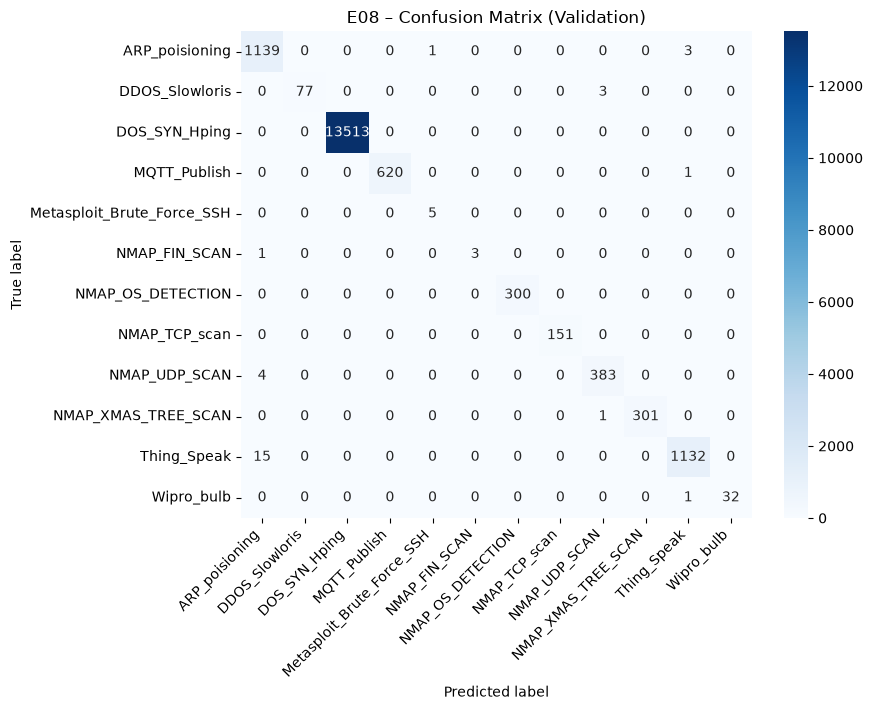

In [ ]:
labels = e08_model.named_steps["classifier"].classes_
cm = confusion_matrix(y_valid, y_pred, labels=labels)

plt.figure(figsize=(max(9, len(labels) * 0.7), max(7, len(labels) * 0.6)))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=labels, yticklabels=labels
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("E08 – Confusion Matrix (Validation)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()